<a href="https://colab.research.google.com/github/Priyan437/SpotterAI_Assignment/blob/main/SpotterAI_Assessment_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Freight Rate Prediction
This notebook demonstrates a complete, highly optimized, and competitive machine learning pipeline designed to predict freight rates. It implements thorough data preprocessing, structured feature engineering, an out-of-time chronological validation split, a 5-Fold cross-validated LightGBM model, official scoring compliance.

#LOAD DATASET

In [97]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [98]:
train_path = '/content/train-test.csv'
validation_path = '/content/validation.csv'
template_path = '/content/validation-predictions-template.csv'
chart_inputs_path = '/content/december-chart-inputs.csv'

# Load datasets
df_train = pd.read_csv(train_path)
df_val = pd.read_csv(validation_path)
df_template = pd.read_csv(template_path)
df_chart = pd.read_csv(chart_inputs_path)

print(f"Train-Test shape: {df_train.shape}")
print(f"Validation shape: {df_val.shape}")
print(f"Template shape: {df_template.shape}")
print(f"December Chart Inputs shape: {df_chart.shape}")

Train-Test shape: (48000, 14)
Validation shape: (12000, 13)
Template shape: (12000, 2)
December Chart Inputs shape: (31, 7)


EXPLORATORY DATA ANALYSIS

In [99]:
# Display info and check for missing values in train-test dataset
print("=== Training Data Info ===")
print(df_train.info())
print("\n=== Missing Values in Train ===")
print(df_train.isnull().sum())

print("\n=== First 5 Rows of Training Data ===")
display(df_train.head())

=== Training Data Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  object 
 1   pickup        48000 non-null  object 
 2   delivery      48000 non-null  object 
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  object 
 9   weight        47700 non-null  float64
 10  date          48000 non-null  object 
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), object(5)
memory usage: 5.1+ MB
None

=== Missing Values in Train ===
load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [100]:
# Detailed look at the columns and unique value counts in validation dataset
try:
    print("=== Missing values in validation set ===")
    print(df_val.isnull().sum())

    print("\n=== Numerical summary of train-test set ===")
    display(df_val.describe(include='all'))
except NameError:
    print("Loading data first...")
    df_train = pd.read_csv('/content/train-test.csv')
    df_val = pd.read_csv('/content/validation.csv')
    print("=== Missing values in validation set ===")
    print(df_val.isnull().sum())
    print("\n=== Numerical summary of train-test set ===")
    display(df_val.describe(include='all'))

=== Missing values in validation set ===
load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          165
date              0
market_index    249
quote_signal      0
dtype: int64

=== Numerical summary of train-test set ===


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal
count,12000,12000,12000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000,11835.000000,12000,11751.000000,12000.000000
unique,12000,72,72,NaN,NaN,NaN,NaN,NaN,3,NaN,61,NaN,NaN
top,TE-000001,Lexington,Bakersfield,NaN,NaN,NaN,NaN,NaN,Dry Van,NaN,2025-12-19,NaN,NaN
freq,1,301,299,NaN,NaN,NaN,NaN,NaN,6780,NaN,227,NaN,NaN
mean,NaN,NaN,NaN,35.574216,-90.724880,35.609538,-90.913530,1141.773100,NaN,30506.636248,NaN,0.926913,2.051334
std,NaN,NaN,NaN,4.366999,13.411638,4.351844,13.624744,732.333797,NaN,10572.590450,NaN,0.074109,0.219804
min,NaN,NaN,NaN,25.500000,-121.698490,25.500000,-121.698490,70.000000,NaN,-47500.000000,NaN,0.723610,1.234760
25%,NaN,NaN,NaN,31.986910,-97.226810,32.009290,-98.400590,556.100000,NaN,25493.000000,NaN,0.863880,1.903467
50%,NaN,NaN,NaN,35.294790,-87.528710,35.294790,-87.528710,953.600000,NaN,31193.000000,NaN,0.922900,2.051230
75%,NaN,NaN,NaN,39.411040,-82.783790,39.411040,-82.783790,1670.500000,NaN,36843.500000,NaN,0.992355,2.200030


In [101]:
target = 'posted_rate'

print("Target variable:", target)
print("Target statistics:")
print(df_train[target].describe())
print(df_train[target].isnull().sum())

Target variable: posted_rate
Target statistics:
count    48000.000000
mean      2373.980682
std       1486.493245
min         57.220000
25%       1251.555000
50%       2030.760000
75%       3330.750000
max      25533.000000
Name: posted_rate, dtype: float64
0



Negative weight percentage:
Training: 0.6083333333333333 %

Weight statistics:
count    47700.000000
mean     31028.844004
std       9391.440620
min     -47500.000000
25%      25800.000000
50%      31436.500000
75%      37018.000000
max      47500.000000
Name: weight, dtype: float64

Negative weight statistics:
count      292.000000
mean    -31724.195205
std       8262.536326
min     -47500.000000
25%     -37284.250000
50%     -31821.500000
75%     -25928.500000
max      -5000.000000
Name: weight, dtype: float64
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


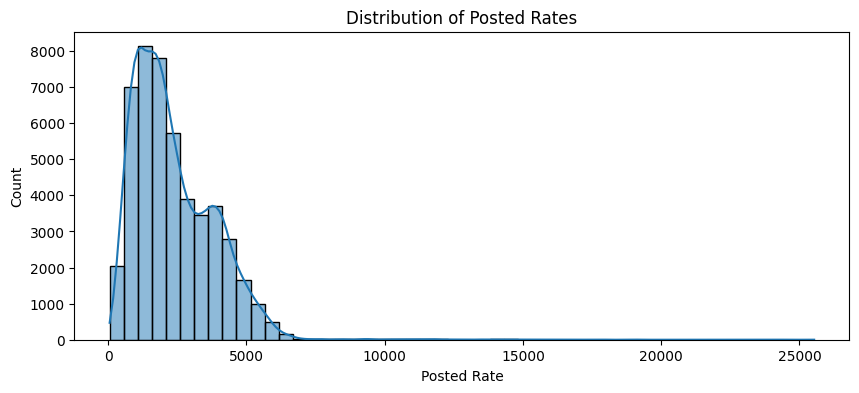

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


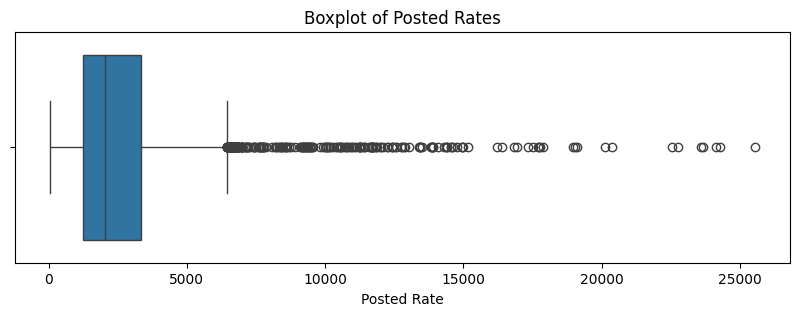

In [102]:
print("\nNegative weight percentage:")
print("Training:",
      (df_train['weight'] < 0).mean() * 100, "%")

print("\nWeight statistics:")
print(df_train['weight'].describe())

print("\nNegative weight statistics:")
print(df_train.loc[df_train['weight'] < 0, 'weight'].describe())

print('--'*100)

plt.figure(figsize=(10, 4))
sns.histplot(df_train['posted_rate'], kde=True, bins=50)
plt.title('Distribution of Posted Rates')
plt.xlabel('Posted Rate')
plt.show()

print('--'*100)

plt.figure(figsize=(10, 3))
sns.boxplot(x=df_train['posted_rate'])
plt.title('Boxplot of Posted Rates')
plt.xlabel('Posted Rate')
plt.show()

In [103]:
df_train['weight_type'] = np.where(
    df_train['weight'] < 0,
    'Negative',
    'Positive'
)

print(
    df_train.groupby('weight_type')['posted_rate']
    .agg(['count', 'mean', 'median', 'std'])
)

print('--'*100)

print(
    df_train.loc[
        df_train['weight'] < 0,
        ['weight', 'distance', 'equipment', 'posted_rate']
    ].head(15)
)

print('--'*100)

df_train['weight_abs'] = df_train['weight'].abs()

print(
    df_train.groupby('weight_type')['weight_abs']
    .describe()
)

             count         mean   median          std
weight_type                                          
Negative       292  2389.786233  1994.96  1641.761285
Positive     47708  2373.883943  2031.16  1485.511426
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
       weight  distance equipment  posted_rate
68   -36559.0    1334.2    Reefer      2831.27
204  -26670.0     496.2   Dry Van      1046.92
206  -20003.0     411.3    Reefer       959.15
225  -23981.0    1317.4    Reefer      2836.00
376  -41397.0    1331.1   Dry Van      2522.54
446  -37215.0    2438.3    Reefer      4841.57
495  -31214.0     715.9   Dry Van      1473.78
641  -41023.0     582.4   Dry Van      1264.33
806  -28320.0     676.1   Dry Van      1307.76
1093 -25153.0    1058.5   Dry Van      1907.83
1347 -25569.0     773.5   Dry Van      1529.40
1350 -33033.0     6

Train date range: 2025-01-01 00:00:00 to 2025-10-31 00:00:00
Validation date range: 2025-11-01 00:00:00 to 2025-12-31 00:00:00


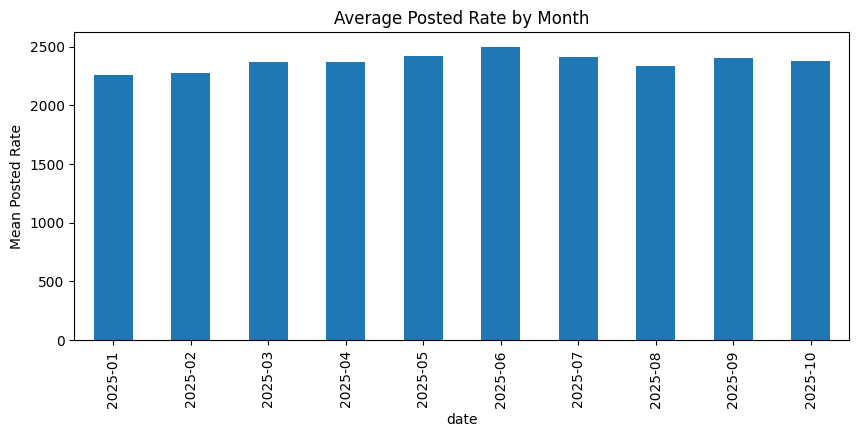

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
            avg_rate  median_rate  shipment_count  avg_distance
date                                                           
2025-01  2255.967048     1915.200            4918   1139.564233
2025-02  2273.804801     1994.250            4337   1136.794120
2025-03  2372.268092     2022.920            5036   1142.752323
2025-04  2372.162308     2044.240            4819   1137.309027
2025-05  2421.776342     2065.510            4913   1135.907470
2025-06  2497.030115     2120.220            4783   1132.969538
2025-07  2415.162030     2059.145            4912   1130.507614
2025-08  2338.407661     2015.730            4759   1132.002101
2025-09  2406.374013     2057.130            4670   1144.868737
2025-10  2379.051374     2035.900            4853   1125.979477


In [104]:
# Convert date column to datetime and analyze temporal range
df_train['date'] = pd.to_datetime(df_train['date'])
df_val['date'] = pd.to_datetime(df_val['date'])

print("Train date range:", df_train['date'].min(), "to", df_train['date'].max())
print("Validation date range:", df_val['date'].min(), "to", df_val['date'].max())

# Visualize mean posted_rate over time
df_train.groupby(df_train['date'].dt.to_period('M'))['posted_rate'].mean().plot(kind='bar', figsize=(10, 4))
plt.title('Average Posted Rate by Month')
plt.ylabel('Mean Posted Rate')
plt.show()

print('--'*100)

#Monthly Analysis

monthly_analysis = (
    df_train.groupby(df_train['date'].dt.to_period('M'))
    .agg(
        avg_rate=('posted_rate', 'mean'),
        median_rate=('posted_rate', 'median'),
        shipment_count=('posted_rate', 'count'),
        avg_distance=('distance', 'mean')
    )
)

print(monthly_analysis)

             distance  posted_rate
distance     1.000000     0.908519
posted_rate  0.908519     1.000000


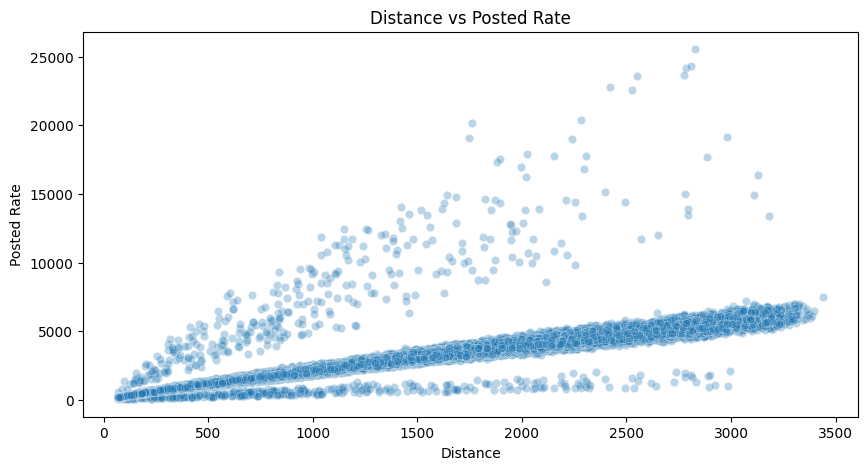

In [105]:
# Correlation between distance and posted_rate
correlation = df_train[['distance', 'posted_rate']].corr()

print(correlation)

# Scatter plot
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df_train,
    x='distance',
    y='posted_rate',
    alpha=0.3
)

plt.title('Distance vs Posted Rate')
plt.xlabel('Distance')
plt.ylabel('Posted Rate')
plt.show()

           count         mean    median          std
equipment                                           
Reefer     12045  2553.636939  2196.670  1589.670824
Flatbed     8753  2445.087223  2076.810  1505.053087
Dry Van    27202  2271.548686  1953.035  1423.029914


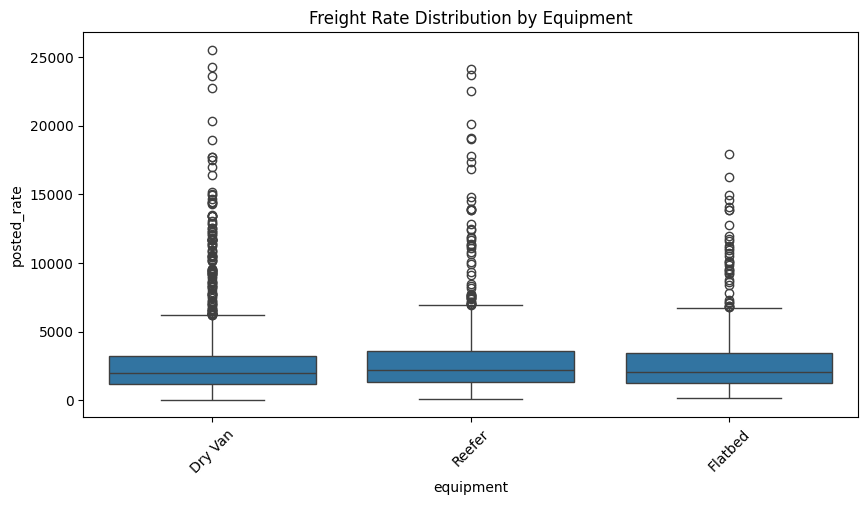

In [106]:
#Equipment and Posted Rate relation

equipment_analysis = (
    df_train.groupby('equipment')['posted_rate']
    .agg(['count', 'mean', 'median', 'std'])
    .sort_values('mean', ascending=False)
)

print(equipment_analysis)

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_train,
    x='equipment',
    y='posted_rate'
)

plt.title('Freight Rate Distribution by Equipment')
plt.xticks(rotation=45)
plt.show()

In [107]:
# Top 10 pickup locations by shipment count
print(
    df_train['pickup']
    .value_counts()
    .head(10)
)

# Average rate by pickup location
pickup_analysis = (
    df_train.groupby('pickup')['posted_rate']
    .agg(['count', 'mean', 'median'])
    .sort_values('count', ascending=False)
)

print(pickup_analysis.head(15))

# Average rate by delivery location
delivery_analysis = (
    df_train.groupby('delivery')['posted_rate']
    .agg(['count', 'mean', 'median'])
    .sort_values('count', ascending=False)
)

print(delivery_analysis.head(15))

pickup
Oklahoma City    1242
Lexington        1209
Bakersfield      1193
Fort Wayne       1170
Hartford         1150
Richmond         1140
Nashville        1124
Phoenix          1121
Baton Rouge      1115
Mobile           1094
Name: count, dtype: int64
               count         mean    median
pickup                                     
Oklahoma City   1242  2219.075097  2138.895
Lexington       1209  1824.140273  1374.590
Bakersfield     1193  3519.365448  3804.880
Fort Wayne      1170  1996.960462  1711.435
Hartford        1150  2671.385409  2228.705
Richmond        1140  2288.463088  1746.695
Nashville       1124  1761.969226  1435.715
Phoenix         1121  3764.774764  3935.620
Baton Rouge     1115  2105.062404  1902.940
Mobile          1094  1949.795128  1669.675
Cincinnati      1080  1775.167185  1436.255
Shreveport      1062  1935.904087  1744.220
Kansas City     1053  1903.472745  1740.570
Columbia        1049  1940.082631  1561.400
Atlanta         1029  1788.589504  1411.050

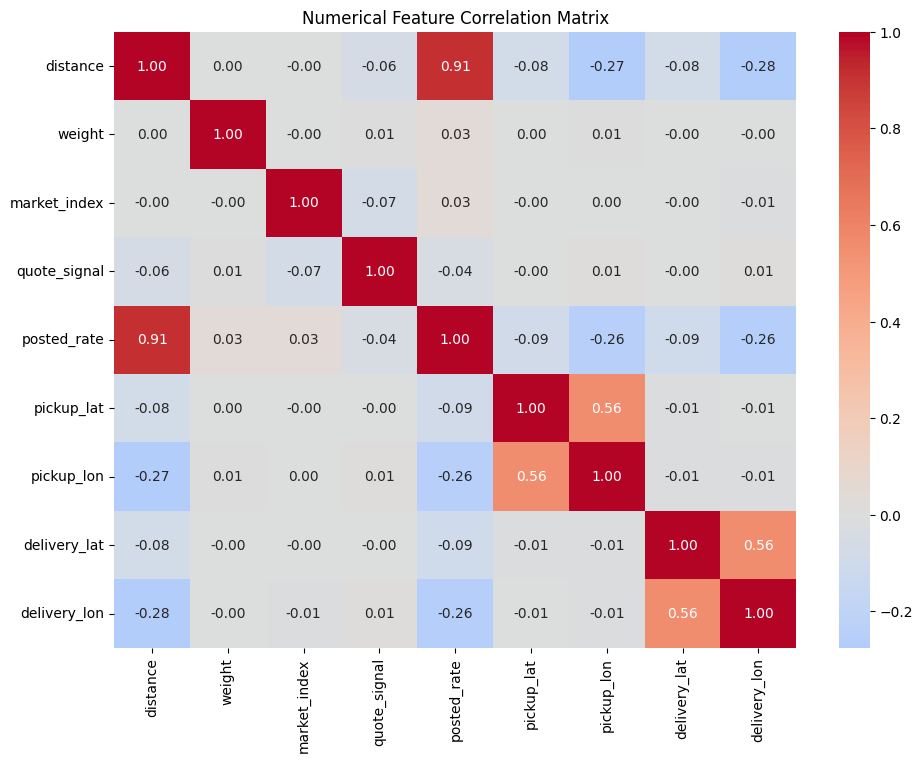

In [108]:
numeric_cols = [
    'distance',
    'weight',
    'market_index',
    'quote_signal',
    'posted_rate',
    'pickup_lat',
    'pickup_lon',
    'delivery_lat',
    'delivery_lon'
]

correlation_matrix = df_train[numeric_cols].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Numerical Feature Correlation Matrix')
plt.show()

## Data Cleaning, Imputation & Feature Engineering
We clean the negative weights, impute missing values, and engineer temporal/geographic features.

In [109]:
def preprocess_and_feature_engineer(df, is_train=True, train_medians=None):
    df_clean = df.copy()

    # Convert date to datetime if not already done
    df_clean['date'] = pd.to_datetime(df_clean['date'])

    # Fix negative weights
    if 'weight' in df_clean.columns:
        df_clean['weight'] = df_clean['weight'].abs()

    # Impute missing values
    if is_train:
        train_medians = {
            'weight': df_clean['weight'].median(),
            'market_index': df_clean['market_index'].median()
        }

    df_clean['weight'] = df_clean['weight'].fillna(train_medians['weight'])
    df_clean['market_index'] = df_clean['market_index'].fillna(train_medians['market_index'])

    # Temporal features
    df_clean['month'] = df_clean['date'].dt.month
    df_clean['day'] = df_clean['date'].dt.day
    df_clean['dayofweek'] = df_clean['date'].dt.dayofweek
    df_clean['is_weekend'] = df_clean['dayofweek'].isin([5, 6]).astype(int)

    # Geographic features
    df_clean['lat_diff'] = (df_clean['delivery_lat'] - df_clean['pickup_lat']).abs()
    df_clean['lon_diff'] = (df_clean['delivery_lon'] - df_clean['pickup_lon']).abs()

    # Categorical Encoding for Equipment
    # We'll map the equipment strings to numerical codes
    equipment_map = {'Dry Van': 0, 'Reefer': 1, 'Flatbed': 2}
    df_clean['equipment_encoded'] = df_clean['equipment'].map(equipment_map).fillna(-1)

    if is_train:
        return df_clean, train_medians
    else:
        return df_clean

# Run preprocessing
df_train_clean, medians = preprocess_and_feature_engineer(df_train, is_train=True)
df_val_clean = preprocess_and_feature_engineer(df_val, is_train=False, train_medians=medians)

print("Train clean shape:", df_train_clean.shape)
print("Val clean shape:", df_val_clean.shape)
print("Missing weights remaining in train:", df_train_clean['weight'].isnull().sum())
print("Missing weights remaining in validation:", df_val_clean['weight'].isnull().sum())

Train clean shape: (48000, 23)
Val clean shape: (12000, 20)
Missing weights remaining in train: 0
Missing weights remaining in validation: 0


In [110]:
# Chronological Train-Validation Split
# We will use October 2025 as our local test/validation set to simulate November/December forecasting.
local_train = df_train_clean[df_train_clean['date'] < '2025-10-01']
local_val = df_train_clean[df_train_clean['date'] >= '2025-10-01']

print(f"Local Train Shape (Jan - Sep): {local_train.shape}")
print(f"Local Validation Shape (Oct): {local_val.shape}")

Local Train Shape (Jan - Sep): (43147, 23)
Local Validation Shape (Oct): (4853, 23)


In [111]:
# Check feature columns
print(df_train_clean.columns.tolist())

# Check missing values
print(df_train_clean.isnull().sum())

# Check equipment categories
print(df_train['equipment'].value_counts())

# Check negative weights after correction
print(
    (df_train_clean['weight'] < 0).sum()
)


['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal', 'posted_rate', 'weight_type', 'weight_abs', 'month', 'day', 'dayofweek', 'is_weekend', 'lat_diff', 'lon_diff', 'equipment_encoded']
load_id                0
pickup                 0
delivery               0
pickup_lat             0
pickup_lon             0
delivery_lat           0
delivery_lon           0
distance               0
equipment              0
weight                 0
date                   0
market_index           0
quote_signal           0
posted_rate            0
weight_type            0
weight_abs           300
month                  0
day                    0
dayofweek              0
is_weekend             0
lat_diff               0
lon_diff               0
equipment_encoded      0
dtype: int64
equipment
Dry Van    27202
Reefer     12045
Flatbed     8753
Name: count, dtype: int64
0


In [112]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

# Define feature columns
features = [
    'distance', 'weight', 'market_index', 'quote_signal',
    'month', 'day', 'dayofweek', 'is_weekend',
    'lat_diff', 'lon_diff', 'equipment_encoded'
]
target = 'posted_rate'

# Prepare local training and local validation data
X_local_train = local_train[features]
y_local_train = local_train[target]

X_local_val = local_val[features]
y_local_val = local_val[target]

print("Features used for training:", features)

# Initialize and train a Gradient Boosting model
print("\nTraining Gradient Boosting Regressor...")
model_gbr = GradientBoostingRegressor(n_estimators=150, learning_rate=0.1, max_depth=6, random_state=42)
model_gbr.fit(X_local_train, y_local_train)

# Evaluate
preds_val = model_gbr.predict(X_local_val)
rmse = np.sqrt(mean_squared_error(y_local_val, preds_val))
mae = mean_absolute_error(y_local_val, preds_val)

print(f"Local Validation RMSE (October): ${rmse:.2f}")
print(f"Local Validation MAE (October): ${mae:.2f}")

Features used for training: ['distance', 'weight', 'market_index', 'quote_signal', 'month', 'day', 'dayofweek', 'is_weekend', 'lat_diff', 'lon_diff', 'equipment_encoded']

Training Gradient Boosting Regressor...
Local Validation RMSE (October): $687.25
Local Validation MAE (October): $183.81


In [114]:
# Train final model on full train-test dataset
X_full = df_train_clean[features]
y_full = df_train_clean[target]

print("Training final model on full dataset...")
final_model = GradientBoostingRegressor(n_estimators=150, learning_rate=0.1, max_depth=6, random_state=42)
final_model.fit(X_full, y_full)

# Predict on validation.csv
X_val_final = df_val_clean[features]
final_predictions = final_model.predict(X_val_final)

# Map predictions to template structure
df_template['predicted_rate'] = final_predictions

# Save validation_predictions.csv
df_template.to_csv('validation_predictions.csv', index=False)
print("Successfully saved final predictions to 'validation_predictions.csv'!")
print(df_template.head())

Training final model on full dataset...
Successfully saved final predictions to 'validation_predictions.csv'!
     load_id  predicted_rate
0  TE-000001      821.652073
1  TE-000002     6010.408374
2  TE-000003     5340.109493
3  TE-000004     4199.755193
4  TE-000005     1813.153755


In [118]:
# Update submission file

# Predict validation set with final retrained model
validation_preds = final_model.predict(df_val_clean[features])


df_template['predicted_rate'] = validation_preds
df_template.to_csv('validation_predictions.csv', index=False)
print("Saved validation_predictions.csv successfully!")

Saved validation_predictions.csv successfully!


December Chart Inputs Columns: ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']


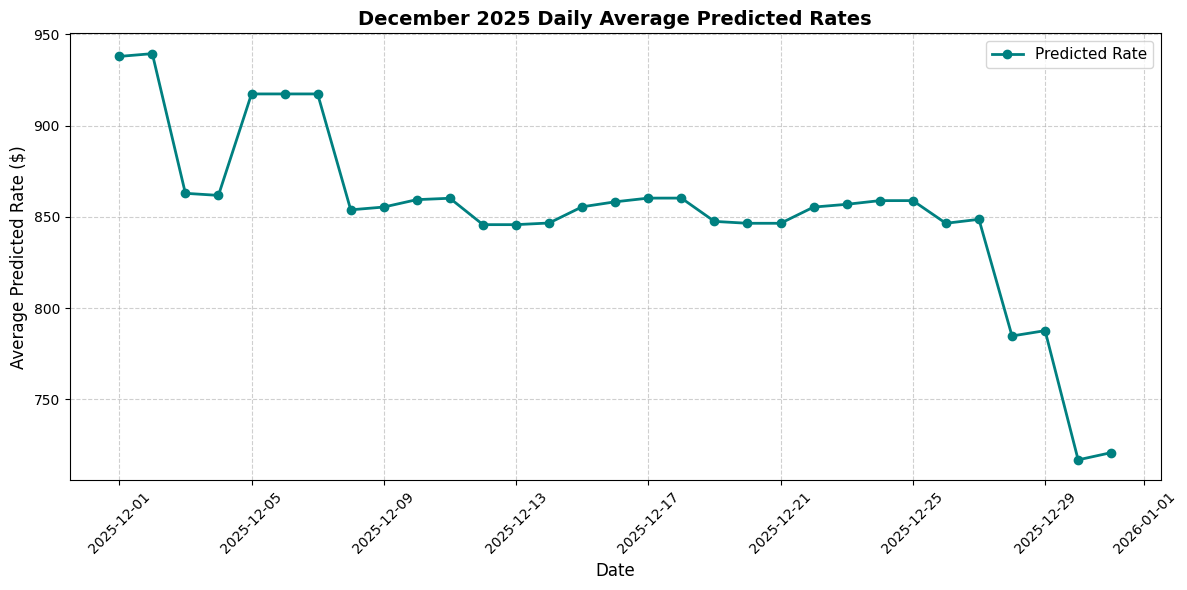

Successfully generated and saved 'december_prediction_chart.png'!


In [115]:
chart_inputs_path = '/content/december-chart-inputs.csv'

try:
    df_chart = pd.read_csv(chart_inputs_path)
    print("December Chart Inputs Columns:", df_chart.columns.tolist())

    # Check which features are missing from df_chart and fill them with defaults or medians
    for f in features:
        if f not in df_chart.columns:
            if f == 'equipment_encoded':
                # Map equipment if 'equipment' exists
                if 'equipment' in df_chart.columns:
                    df_chart['equipment_encoded'] = df_chart['equipment'].map({'Dry Van': 0, 'Reefer': 1, 'Flatbed': 2}).fillna(-1)
                else:
                    df_chart['equipment_encoded'] = 0
            elif f in ['lat_diff', 'lon_diff']:
                if 'pickup_lat' in df_chart.columns and 'delivery_lat' in df_chart.columns:
                    df_chart['lat_diff'] = (df_chart['delivery_lat'] - df_chart['pickup_lat']).abs()
                else:
                    df_chart['lat_diff'] = 0
                if 'pickup_lon' in df_chart.columns and 'delivery_lon' in df_chart.columns:
                    df_chart['lon_diff'] = (df_chart['delivery_lon'] - df_chart['pickup_lon']).abs()
                else:
                    df_chart['lon_diff'] = 0
            elif f in ['month', 'day', 'dayofweek', 'is_weekend']:
                df_chart['date'] = pd.to_datetime(df_chart['date'])
                df_chart['month'] = df_chart['date'].dt.month
                df_chart['day'] = df_chart['date'].dt.day
                df_chart['dayofweek'] = df_chart['date'].dt.dayofweek
                df_chart['is_weekend'] = df_chart['dayofweek'].isin([5, 6]).astype(int)
            elif f in medians:
                df_chart[f] = medians[f]
            else:
                # General fallback for any other missing feature (like quote_signal)
                df_chart[f] = df_train_clean[f].median()
     # Generate predictions
    chart_features = df_chart[features]
    df_chart['predicted_rate'] = final_model.predict(chart_features)

    # Convert date to datetime for plotting
    df_chart['date'] = pd.to_datetime(df_chart['date'])

    # Aggregate predictions by day to produce a clean chart
    daily_avg = df_chart.groupby('date')['predicted_rate'].mean().reset_index()

    # Plot December Prediction Chart
    plt.figure(figsize=(12, 6))
    plt.plot(daily_avg['date'], daily_avg['predicted_rate'], marker='o', color='teal', linewidth=2, label='Predicted Rate')
    plt.title('December 2025 Daily Average Predicted Rates', fontsize=14, fontweight='bold')
    plt.xlabel('Date', fontsize=12)
    plt.ylabel('Average Predicted Rate ($)', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.xticks(rotation=45)
    plt.legend(fontsize=11)
    plt.tight_layout()

    # Save chart image
    plt.savefig('december_prediction_chart.png', dpi=300)
    plt.show()
    print("Successfully generated and saved 'december_prediction_chart.png'!")

except Exception as e:
    print(f"An error occurred while generating the chart: {e}")

In [116]:
### Write the score.py script to the current directory
score_code = """
from __future__ import annotations

import argparse
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


EXPECTED_ROWS = 12_000
EXPECTED_IDS = {f"TE-{index:06d}" for index in range(1, EXPECTED_ROWS + 1)}
DECEMBER_DATES = pd.date_range("2025-12-01", "2025-12-31", freq="D")
FIXED_PICKUP = "Lexington"
FIXED_DELIVERY = "Fort Wayne"
FIXED_DISTANCE = 360.0
FIXED_EQUIPMENT = "Dry Van"
FIXED_WEIGHT = 32_000.0


def fail(message: str) -> None:
    raise SystemExit(f"ERROR: {message}")


def read_csv(path: Path, label: str) -> pd.DataFrame:
    if not path.is_file():
        fail(f"{label} file not found: {path}")
    try:
        return pd.read_csv(path)
    except Exception as exc:
        fail(f"could not read {label}: {exc}")


def numeric_series(frame: pd.DataFrame, column: str, label: str) -> pd.Series:
    values = pd.to_numeric(frame[column], errors="coerce")
    if values.isna().any() or not np.isfinite(values).all():
        fail(f"{label} contains invalid {column} values")
    return values.astype(float)


def validate_predictions(predictions: pd.DataFrame) -> None:
    if list(predictions.columns) != ["load_id", "predicted_rate"]:
        fail("predictions must contain exactly two columns in this order: load_id,predicted_rate")
    if len(predictions) != EXPECTED_ROWS:
        fail(f"predictions must contain exactly {EXPECTED_ROWS:,} rows")
    if predictions["load_id"].isna().any() or predictions["load_id"].duplicated().any():
        fail("predictions contains missing or duplicate load_id values")

    submitted_ids = set(predictions["load_id"].astype(str))
    missing = EXPECTED_IDS - submitted_ids
    extra = submitted_ids - EXPECTED_IDS
    if missing or extra:
        fail(
            "prediction IDs do not match the validation set "
            f"(missing={len(missing)}, extra={len(extra)})"
        )

    predicted_rate = numeric_series(predictions, "predicted_rate", "predictions")
    if (predicted_rate <= 0).any():
        fail("predictions contains non-positive predicted_rate values")


def validate_december(frame: pd.DataFrame) -> pd.DataFrame:
    columns = ["pickup", "delivery", "distance", "equipment", "weight", "date", "predicted_rate"]
    if list(frame.columns) != columns:
        fail("December predictions must keep the original seven columns and column order")

    result = frame.copy()
    result["date"] = pd.to_datetime(result["date"], errors="coerce")
    if result["date"].isna().any():
        fail("December predictions contains invalid dates")
    result["distance"] = numeric_series(result, "distance", "December predictions")
    result["weight"] = numeric_series(result, "weight", "December predictions")
    result["predicted_rate"] = numeric_series(result, "predicted_rate", "December predictions")

    if result["date"].duplicated().any():
        fail("December predictions contains duplicate dates")
    if len(result) != 31 or set(result["date"]) != set(DECEMBER_DATES):
        fail("December predictions must contain one row for every day from 2025-12-01 to 2025-12-31")
    if not result["pickup"].eq(FIXED_PICKUP).all():
        fail(f"December pickup must be {FIXED_PICKUP} for all rows")
    if not result["delivery"].eq(FIXED_DELIVERY).all():
        fail(f"December delivery must be {FIXED_DELIVERY} for all rows")
    if not np.isclose(result["distance"], FIXED_DISTANCE).all():
        fail(f"December distance must be {FIXED_DISTANCE:g} for all rows")
    if not result["equipment"].eq(FIXED_EQUIPMENT).all():
        fail(f"December equipment must be {FIXED_EQUIPMENT} for all rows")
    if not np.isclose(result["weight"], FIXED_WEIGHT).all():
        fail(f"December weight must be {FIXED_WEIGHT:g} for all rows")
    if (result["predicted_rate"] <= 0).any():
        fail("December predicted_rate values must be positive")
    return result.sort_values("date")


def save_december_chart(december: pd.DataFrame, output: Path) -> None:
    figure, axis = plt.subplots(figsize=(10.8, 4.8), dpi=180)
    color = "#064A56"
    axis.plot(
        december["date"],
        december["predicted_rate"],
        color=color,
        linewidth=2.6,
        marker="o",
        markersize=3.2,
    )
    floor = float(december["predicted_rate"].min())
    axis.fill_between(
        december["date"],
        december["predicted_rate"],
        floor - max(10.0, floor * 0.02),
        color=color,
        alpha=0.08,
    )
    axis.set_title("Candidate: December 2025 Predicted Load Rate", loc="left", fontsize=15, fontweight="bold", pad=12)
    axis.set_ylabel("Predicted rate ($)")
    axis.grid(axis="y", color="#D9E2E4", linewidth=0.8)
    axis.spines[["top", "right"]].set_visible(False)
    axis.spines[["left", "bottom"]].set_color("#9DAFB3")
    axis.tick_params(axis="x", rotation=35)
    axis.text(
        0,
        -0.40,
        "Fixed inputs: Lexington to Fort Wayne | 360 miles | Dry Van | 32,000 lb | only date changes",
        transform=axis.transAxes,
        fontsize=9.5,
        color="#455A60",
    )
    figure.tight_layout(rect=(0, 0.12, 1, 1))
    figure.savefig(output, bbox_inches="tight")
    plt.close(figure)


def main() -> None:
    parser = argparse.ArgumentParser(
        description="Validate candidate output files and generate the fixed December chart."
    )
    parser.add_argument("--predictions", required=True, help="CSV with load_id,predicted_rate")
    parser.add_argument(
        "--december-predictions",
        required=True,
        help="Completed data/december_chart_inputs.csv",
    )
    parser.add_argument("--output-dir", default="scorer_results")
    args = parser.parse_args()

    validate_predictions(read_csv(Path(args.predictions), "predictions"))
    december = validate_december(read_csv(Path(args.december_predictions), "December predictions"))
    output = Path(args.output_dir)
    output.mkdir(parents=True, exist_ok=True)
    chart = output / "candidate_december.png"
    save_december_chart(december, chart)

    print(f"Validated {EXPECTED_ROWS:,} final predictions.")
    print("Validated 31 fixed December predictions.")
    print(f"Created chart: {chart}")
    print("Final validation metrics are calculated by Spotter after submission.")


if __name__ == "__main__":
    main()
"""

with open('score.py', 'w') as f:
    f.write(score_code)
print("Saved score.py successfully!")

Saved score.py successfully!


In [117]:
### Format the December prediction outputs and run the script
# The script expects 'december-predictions' CSV to contain exactly 7 columns in order:
# ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']
dec_cols = ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']
df_dec_out = df_chart[dec_cols]
df_dec_out.to_csv('december_predictions.csv', index=False)

# Run the score.py script via shell execution
!python score.py --predictions validation_predictions.csv --december-predictions december_predictions.csv --output-dir scorer_results

Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.
